# Case Study: Modeling the planet Gaia-4b with astrometry and radial velocities

Gaia-4b is a roughly 12 Jupiter mass planet with a period of about 571 days and was first identified as a candidate astrometric exoplanet companion in *Gaia* DR3. It was subsequently observed and confirmed with radial velocity (RV) follow-up from the HPF, NEID, and FIES spectrographs ([Stefansson et al. 2025](https://arxiv.org/abs/2410.05654)). The *Gaia* DR4 data for the host star was released as a part of the [DR4 pre-release](https://www.cosmos.esa.int/web/gaia/dr4-prerelease), so we now have the full astrometric time series to model as well. 

In this case study, we will use `harv` to first model the astrometry data, and then do joint modeling of the astrometry and publicly-available radial velocity data. We will:

1. Model the astrometry alone using `harv`'s rejection sampler and demonstrate how to use both the standard (Campbell) parameterization and the Thiele-Innes parameterization of the planet orbit.
2. Use the best rejection sample(s) returned to start standard MCMC (NUTS) with the {py:class}`~harv.NumpyroSampler`.
3. Add in the RV data from the three instruments (with unknown instrumental offsets between them) and run MCMC on the joint astrometry + RV data.

First, the imports we'll need:

In [1]:
import jax
import numpyro

jax.config.update("jax_enable_x64", True)
numpyro.set_host_device_count(4)

In [2]:
import arviz as az
import astropy.table as at
import matplotlib.pyplot as plt
import numpy as np
import numpyro.distributions as dist
import quaxed.numpy as jnp
from arviz_base import rc_context
from astropy.time import Time
from unxt import Q

import harv
import harv.models as hm
from harv.models.parameterizations import ThieleInnesGaiaAstrometry

%matplotlib inline

## 1. Loading the data

### *Gaia* epoch astrometry

The astrometry file (downloaded from the [DR4 pre-release page](https://www.cosmos.esa.int/web/gaia/dr4-prerelease) but included as a small `ecsv` file in this repo) contains along-scan position measurements grouped by field-of-view transit (the per-CCD measurements have already been combined), along with the scan angle and the (along-scan) parallax factor at each epoch. The observation times are given in days relative to the *Gaia* DR4 reference epoch, which for DR4 is J2017.5 (TCB). We will later combine these data with RV measurements whose times are barycentric Julian dates, so we convert the astrometry times to JD by adding the JD of J2017.5. The two time scales (TCB for *Gaia*, TDB for the RVs) differ by about 20 seconds at this epoch, which we can ignore for a 571-day orbit.

In [3]:
gaia_tbl = at.QTable.read("../data/gaia-dr4-prerelease/Gaia-4.ecsv")
gaia_time = gaia_tbl["relative_time"].to_value("day") + Time("J2017.5", scale="tcb").jd
gaia_tbl.meta

{'parallax_mas': 13.643, 'period_day': 571.3}

The table metadata store the catalog parallax and period, which we will only use as reference values to compare against at the end (we do not use them in the priors).

The table also contains an `excess_noise` column. This is the astrometric excess noise from the single-star astrometric solution, i.e. the extra scatter needed for a model with only position, proper motion, and parallax to fit the data. For Gaia-4, most of that "noise" is the orbit of the planet! So we don't add the excess noise to the uncertainties. Instead, we will fit for a (much smaller) astrometric jitter term along with the orbit.

### Radial velocities

The RV data come from Table 5 of Stefansson et al. (2025), and contain measurements from three instruments (HPF, NEID, FIES). We create a separate {py:class}`~harv.RVData` object for each instrument and package them into a {py:class}`~harv.SourceData` container.

Even though we won't use them until later in the tutorial, we load the RV data now because we want to be sure to handle the reference epoch of each dataset correctly. In `harv`, the orbital phase parameter `phase_peri` is measured relative to the data's reference time `time_ref`, which defaults to the mean observation time. When we combine datasets in a `SourceData` container, `harv` sets all of their reference times to the mean of *all* observation times so that the shared `phase_peri` means the same thing for each dataset. If we fit the astrometry alone with its own reference time, then the phases from that fit would not line up in the joint model. So we define a common time_ref for all datasets:

In [4]:
rv_tbl = at.Table.read("../data/Gaia-4-rv.fits")

time_ref = Q(np.mean(np.concatenate([gaia_time, rv_tbl["BJD"]])), "day")

rv_datasets = {}
for inst in np.unique(rv_tbl["Inst"]):
    tmp = rv_tbl[rv_tbl["Inst"] == inst]
    rv_datasets[inst.decode("utf-8").strip()] = harv.RVData(
        time=Q(tmp["BJD"].astype(np.float64), "day"),
        rv=Q(tmp["RVel"].astype(np.float64), "m/s"),
        rv_err=Q(tmp["e_RVel"].astype(np.float64), "m/s"),
        time_ref=time_ref,
    )
rv_data = harv.SourceData(**rv_datasets)
print("Number of RVs per instrument:")
print({name: d.n_obs for name, d in rv_data.items()})

Number of RVs per instrument:
{'FIES': 5, 'HPF': 10, 'NEID': 8}


 We also set the reference time for the astrometry to the mean of all of the astrometry and RV times from the start:

In [5]:
gaia_data = harv.GaiaAstrometryData(
    time=Q(gaia_time, "day"),
    al_position=Q(gaia_tbl["pos_al"].to_value("mas"), "mas"),
    al_position_err=Q(gaia_tbl["pos_al_err"].to_value("mas"), "mas"),
    scan_angle=Q(gaia_tbl["scan_angle"].to_value("deg"), "deg"),
    parallax_factor=jnp.asarray(gaia_tbl["parallax_factor"], dtype=np.float64),
    time_ref=time_ref,
)
gaia_data.n_obs

93

Let's look at both datasets:

Text(0.5, 1.0, 'Radial velocities')

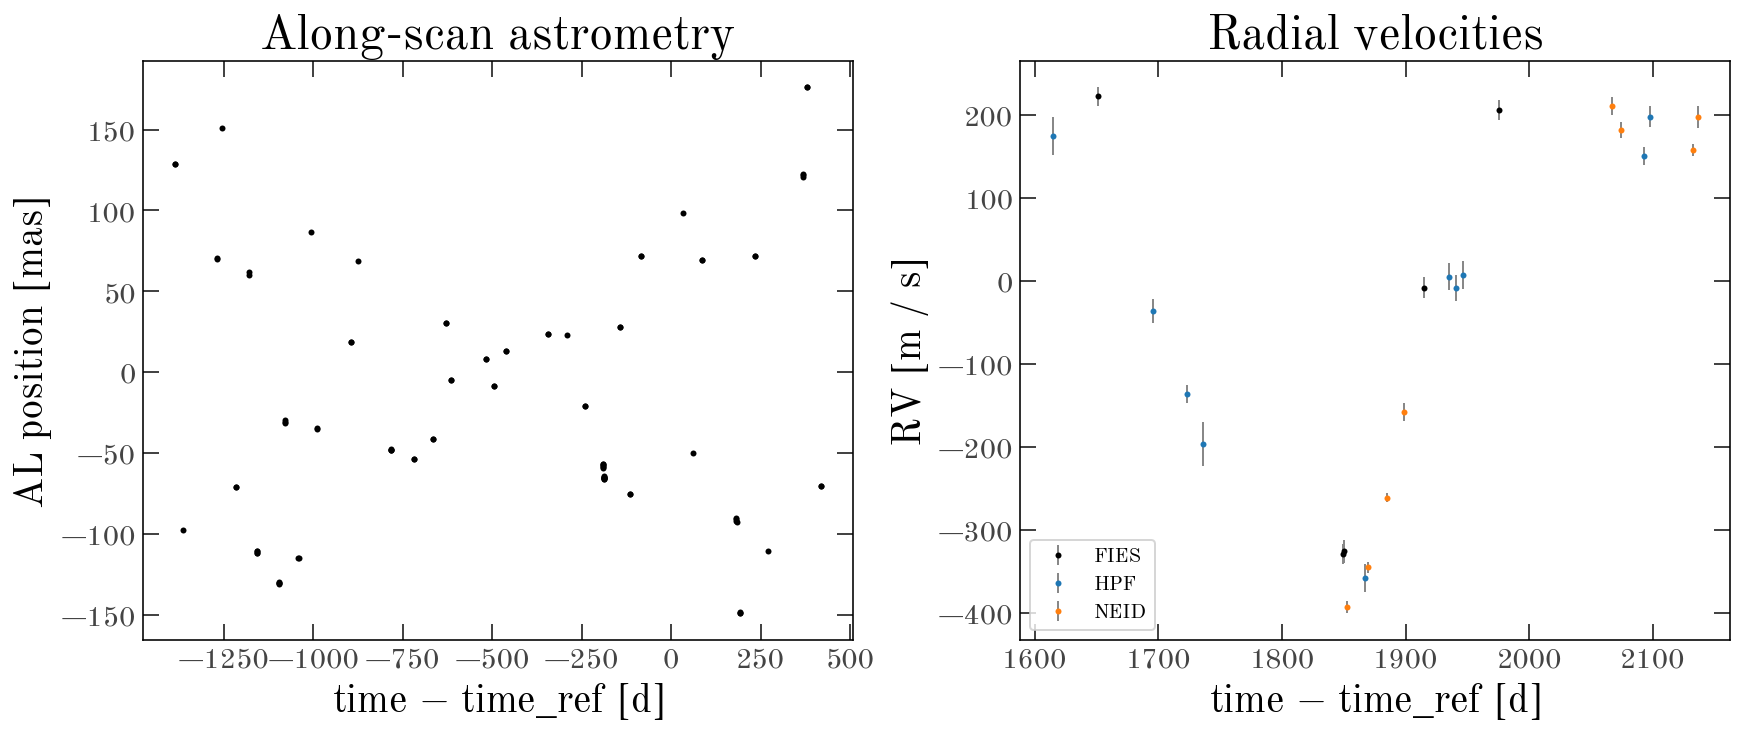

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), layout="constrained")
gaia_data.plot(axes[0], relative_to_time_ref=True)
axes[0].set_title("Along-scan astrometry")
rv_data.plot(ax=axes[1], relative_to_time_ref=True)
axes[1].set_title("Radial velocities")

The along-scan positions are dominated by the proper motion and parallax of the star (the source is about 73 pc away), and the orbital signal is a small perturbation on top of that. The RVs cover a little less than one orbital period, and the measurements from different instruments appear to be offset from one another.

## 2. Modeling the astrometry first with the rejection sampler

### Standard parameterization

We start with the default prior for the standard *Gaia* astrometry parameterization, {py:class}`~harv.models.StandardGaiaAstrometry`. This has six nonlinear parameters (period, eccentricity, phase, argument of pericenter, longitude of the ascending node, and $\cos i$) and six linear parameters (the reference position, proper motion, parallax, and the angular semi-major axis of the photocenter orbit). We use a broad log-uniform period prior from 10 to 2000 days, which covers periods up to about the length of the *Gaia* baseline. The parallax prior is a half-normal that is sampled explicitly rather than marginalized (see {py:meth}`~harv.models.StandardGaiaAstrometry.default_prior`) because the sampled parallax values are used to set a parallax-dependent prior on proper motion and angular semi-major axis so that the prior is fixed in relative velocity and physical (i.e. measured in AU) semi-major axis. We use a half-normal prior for the astrometric jitter parametter. We'll reuse these settings for the other parameterization below.

In [7]:
prior_kwargs = {
    "period_min": Q(10.0, "day"),
    "period_max": Q(2000.0, "day"),
    "sigma_a0": Q(1.0, "AU"),
    "sigma_parallax": Q(50.0, "mas"),
    "sigma_pos": Q(100.0, "mas"),
    "sigma_vtan": Q(100.0, "km/s"),
    "jitter": harv.QD(dist.HalfNormal(0.1), "mas"),
}
std_prior = hm.StandardGaiaAstrometry().default_prior(**prior_kwargs)
astrom_model = harv.GaiaAstrometryModel(extensions=(harv.Jitter(obs_unit="mas"),))

We marginalize over the reference position, proper motion, and semi-major axis. The "`require_evidence_stats`" option tells the sampler to return some evidence statistics so we can inspect how well the rejection sampling did:

In [8]:
std_sampler = harv.RejectionSampler(
    std_prior,
    astrom_model,
    marginalized_names=("ra0", "dec0", "pmra", "pmdec", "semi_major_axis"),
)
std_samples = std_sampler.run(
    gaia_data,
    key=jax.random.key(1),
    n_prior_samples=10_000_000,
    return_logprobs=True,
    return_evidence_stats=True,
)
std_diag = std_samples.acceptance_diagnostics()
print("n samples returned: ", std_samples.n_samples)
print("ESS: ", std_diag["evidence_ess"])
print("Max. ln likelihood: ", std_diag["max_ln_likelihood"])

/var/folders/67/2zgxpmyd2z183j4k6r33nf740000gr/T/ipykernel_93876/744501109.py:6: UserWarning: Under-resolved rejection run: the evidence integral is dominated by ~1.4 effective prior sample(s) of 10000000 (below min_evidence_ess=3), so max_ln_likelihood=92.5 may not have converged and the accepted-sample count (1) is not a reliable posterior size. Increase n_prior_samples (compare max_ln_likelihood across runs to check it stops rising) and/or continue with NumpyroSampler(prior, model).run(data, init_samples=...) to draw the posterior.
  std_samples = std_sampler.run(


n samples returned:  1
ESS:  1.3722025820541057
Max. ln likelihood:  92.50492131055411


Even with ten million prior samples, only a single sample is returned, and the sampler warns us that the evidence integral is dominated by about one effective prior sample. The data are very constraining (the orbit is detected at high signal-to-noise), so the posterior occupies a tiny fraction of the six-dimensional nonlinear prior volume. A rejection sampler is not an efficient way of sampling the posterior in this regime. Before we switch samplers, let's try changing the parameterization and re-running the rejection.

### Thiele-Innes parameterization

The orientation parameters $(\omega, \Omega, \cos i)$ and photocenter ellipse semi-major axis $a_0$ enter the along-scan model only through the four Thiele-Innes constants $(A, B, F, G)$, and the model is linear in those constants. The {py:class}`~harv.models.parameterizations.ThieleInnesGaiaAstrometry` parameterization exploits this by treating $A, B, F, G$ as linear parameters, so only the period, eccentricity, and phase remain nonlinear (plus, here, the parallax and jitter, which we sample explicitly). We construct this parameterization with `from_data()`, which sets the numerical floor used in the Jacobian correction (that converts a prior on the Thiele-Innes constants into a prior on the physical orbital elements) from the data uncertainties. The default prior takes the same arguments as above:

In [9]:
ti_param = ThieleInnesGaiaAstrometry.from_data(gaia_data)
ti_prior = ti_param.default_prior(**prior_kwargs)
ti_model = harv.GaiaAstrometryModel(
    parameterization=ti_param, extensions=(harv.Jitter(obs_unit="mas"),)
)

In [10]:
ti_sampler = harv.RejectionSampler(
    ti_prior,
    ti_model,
    marginalized_names=("ra0", "dec0", "pmra", "pmdec", "ti_A", "ti_B", "ti_F", "ti_G"),
)
ti_samples = ti_sampler.run(
    gaia_data,
    key=jax.random.key(1),
    n_prior_samples=10_000_000,
    return_logprobs=True,
    return_evidence_stats=True,
)
ti_diag = ti_samples.acceptance_diagnostics()
print("n samples returned: ", ti_samples.n_samples)
print("ESS: ", ti_diag["evidence_ess"])
print("Max. ln likelihood: ", ti_diag["max_ln_likelihood"])

n samples returned:  1
ESS:  1.0002650248840728
Max. ln likelihood:  118.17310745127077


/var/folders/67/2zgxpmyd2z183j4k6r33nf740000gr/T/ipykernel_93876/3928972260.py:6: UserWarning: Under-resolved rejection run: the evidence integral is dominated by ~1.0 effective prior sample(s) of 10000000 (below min_evidence_ess=3), so max_ln_likelihood=118.2 may not have converged and the accepted-sample count (1) is not a reliable posterior size. Increase n_prior_samples (compare max_ln_likelihood across runs to check it stops rising) and/or continue with NumpyroSampler(prior, model).run(data, init_samples=...) to draw the posterior.
  ti_samples = ti_sampler.run(


The rejection sampler still only returns one sample, but the maximum log-likelihood found is much higher than with the standard parameterization. With fewer nonlinear dimensions, the same number of prior samples gets much closer to the peak of the likelihood. This is a common situation with high signal-to-noise data when using `harv`'s rejection sampler: the sampler is not going to produce many independent posterior samples, but it is a very good tool for *finding* the mode of the posterior with no initialization, even with a broad period prior. From there, we can switch to MCMC (see the discussion in the {doc}`concepts page <../../concepts>`).

The Thiele-Innes constants are convenient for sampling, but we typically want to report the physical (Campbell) orbital elements. We can convert using {py:meth}`~harv.samplers.Samples.thiele_innes_to_campbell`:

In [11]:
ti_campbell = ti_samples.thiele_innes_to_campbell()
for name in [
    "period",
    "eccentricity",
    "semi_major_axis",
    "cos_i",
    "parallax",
    "jitter",
]:
    print(f"{name}: {ti_campbell[name]}")

period: Quantity([582.94983683], unit='d')
eccentricity: Quantity([0.3594926], unit='')
semi_major_axis: Quantity([0.24698995], unit='mas')
cos_i: Quantity([-0.53587184], unit='')
parallax: Quantity([13.62329073], unit='mas')
jitter: Quantity([0.02375721], unit='mas')


The period is already close to the published P = 571 days, and the parallax is close to the catalog value.

## 3. Refining with MCMC

To continue with standard MCMC, since these data are very constraining, we switch back to the standard parameterization. There are two reasons for this. First, the Thiele-Innes constants can be very correlated, so it is cleaner to sample the physical elements directly. Second, the RV model is not linear in the Thiele-Innes constants, so the joint model in the next section requires the standard parameterization anyway.

Before running MCMC, we use {py:meth}`~harv.NumpyroSampler.optimize` to move the rejection sample to the nearby peak of the posterior. This isn't strictly necessary, but starting the MCMC chains close to the mode peak means that warmup converges faster:

In [12]:
astrom_mcmc_sampler = harv.NumpyroSampler(
    std_prior,
    astrom_model,
    marginalized_names=("ra0", "dec0", "pmra", "pmdec", "semi_major_axis"),
)
astrom_opt = astrom_mcmc_sampler.optimize(ti_campbell, gaia_data, key=jax.random.key(0))
astrom_opt["period"], astrom_opt.reduced_chi2(gaia_data, astrom_model)

(Quantity(Array([578.31123669], dtype=float64), unit='d'),
 Array([1.01709264], dtype=float64))

The reduced $\chi^2$ at the optimized point is close to 1 after this optimization. Now we run MCMC with four chains using NUTS, all initialized from the optimized sample:

In [13]:
astrom_mcmc = astrom_mcmc_sampler.run(
    gaia_data,
    init_samples=astrom_opt,
    key=jax.random.key(123),
    num_chains=4,
    num_warmup=1000,
    num_samples=2000,
    return_logprobs=True,
)

  0%|          | 0/3000 [00:00<?, ?it/s]

  0%|          | 0/3000 [00:00<?, ?it/s]

  0%|          | 0/3000 [00:00<?, ?it/s]

  0%|          | 0/3000 [00:00<?, ?it/s]

In [14]:
astrom_names = [
    "period",
    "eccentricity",
    "cos_i",
    "semi_major_axis",
    "parallax",
    "jitter",
]
az.summary(astrom_mcmc.to_arviz(astrom_names), var_names=astrom_names)

,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
period,577.7,3.73,570,580,3989,4207,1.00,0.059,0.042
eccentricity,0.385,0.076,0.26,0.51,3829,4335,1.00,0.0012,0.0009
cos_i,-0.52,0.0429,-0.59,-0.45,5198,4773,1.00,0.0006,0.00043
semi_major_axis,0.2528,0.0109,0.24,0.27,4497,5472,1.00,0.00016,0.00013
parallax,13.6245,0.0082,14,14,7839,5336,1.00,9.3e-05,6.7e-05
jitter,0.0203,0.00423,0.014,0.027,5499,3817,1.00,5.7e-05,4.2e-05


The chains have converged ($\hat{R} \approx 1$) with plenty of effective samples. Let's look at a corner plot of the posterior samples and the maximum a posteriori orbit compared to the data:

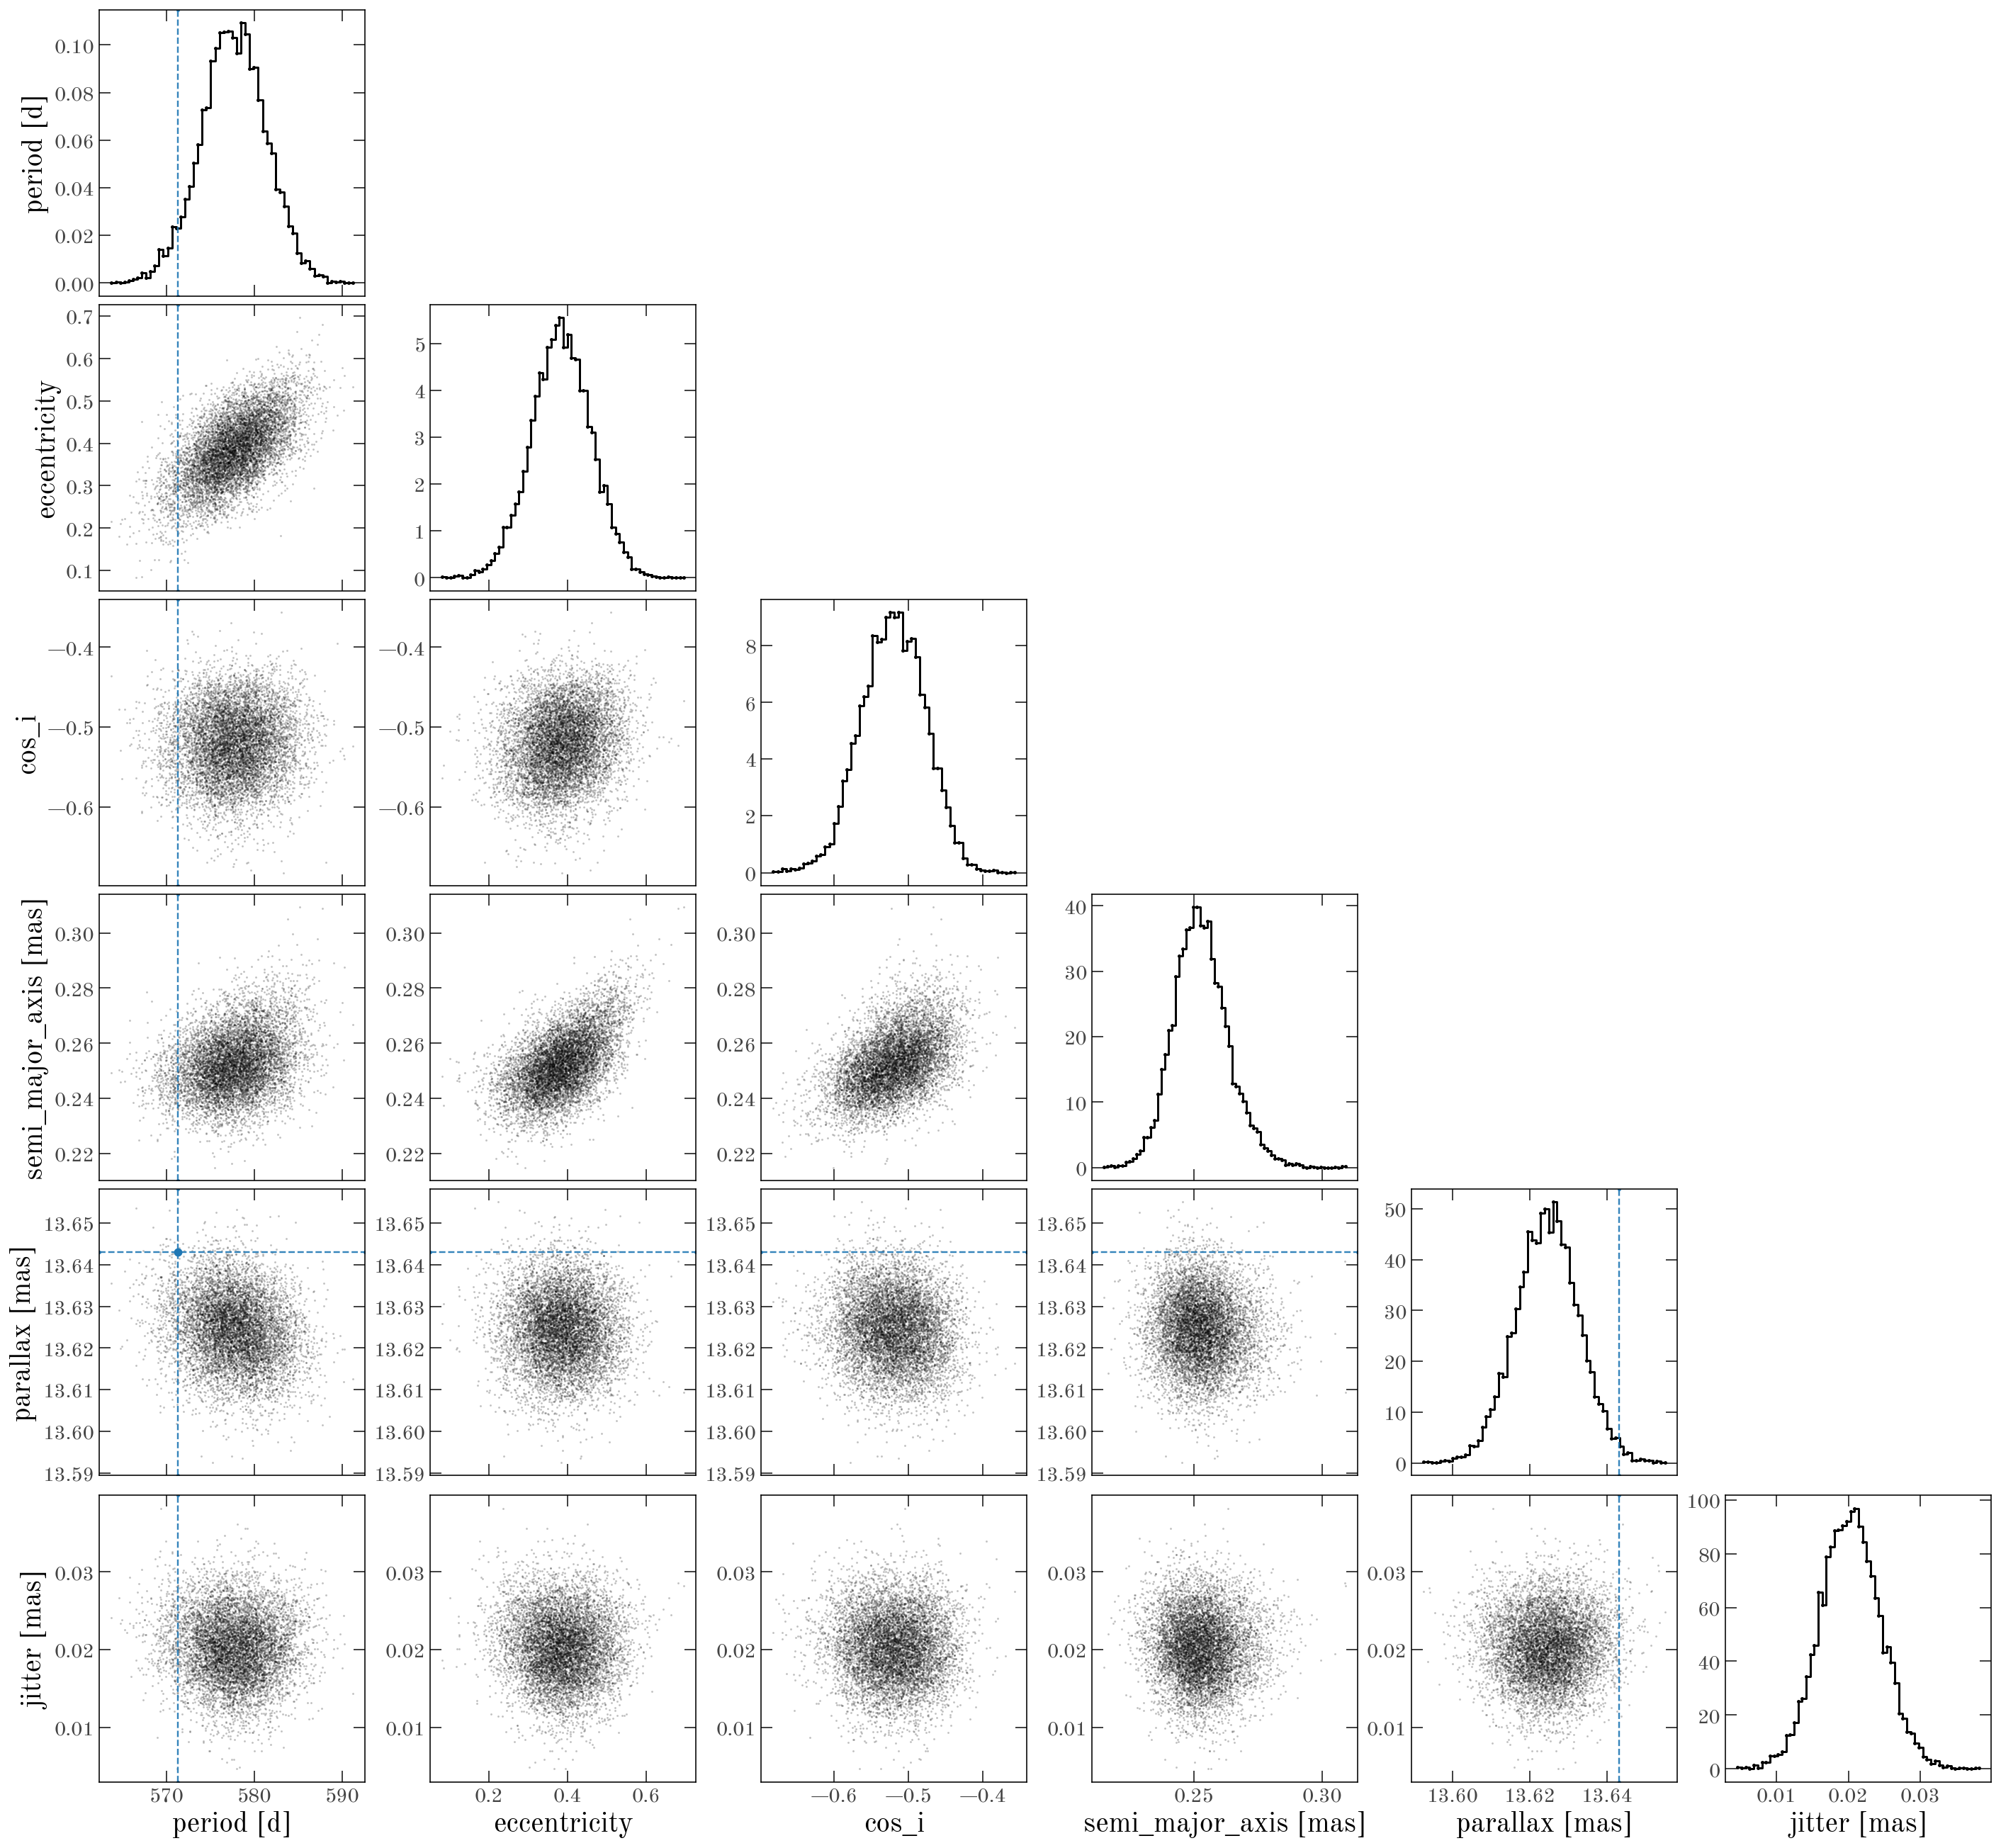

In [15]:
_ = astrom_mcmc.wrap_angles().plot_corner(
    astrom_names,
    truths={
        "period": gaia_tbl.meta["period_day"],
        "parallax": gaia_tbl.meta["parallax_mas"],
    },
    visuals={"scatter": {"alpha": 0.25, "s": 2}},
)

/Users/aprice-whelan/projects/harv/src/harv/plot.py:1295: UserWarning: The figure layout has changed to tight
  fig.tight_layout()


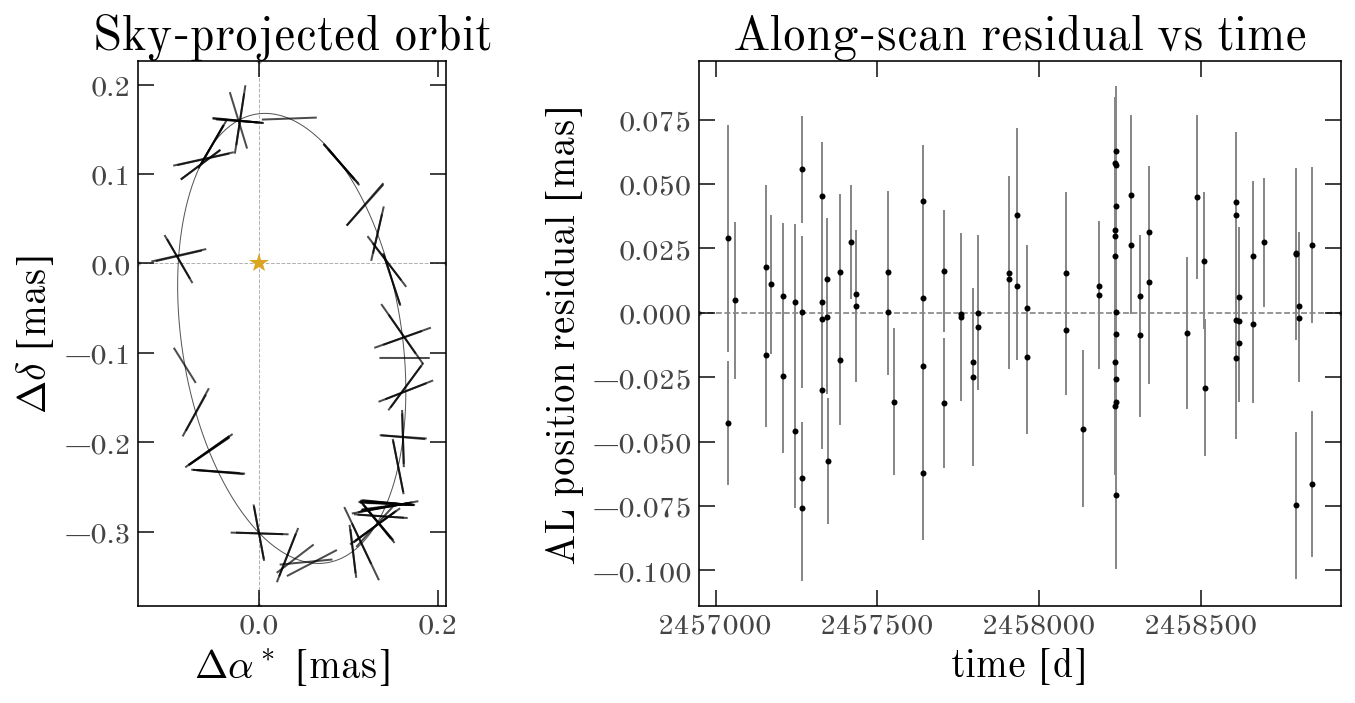

In [16]:
_ = harv.plot.plot_gaia_astrometry(astrom_mcmc.map_sample(), data=gaia_data)

The astrometry data alone constrain the orbit pretty well. The photocenter orbit has a semi-major axis of about 0.25 mas, the period is within about two standard deviations of the published 571.3 days, and the parallax is close to the catalog value.

## 4. Joint astrometry + RV model

Now we incorporate the RV data as well. We first stack the RV datasets into a single `RVData` object and build an indicator matrix that marks which instrument each measurement came from. We use FIES as the reference instrument, so the model includes offsets for HPF and NEID relative to FIES (the FIES zero-point is absorbed into the systemic velocity). These offsets are added to the RV model with a {py:class}`~harv.MultiSurveyOffset` extension, along with an RV jitter term:

In [17]:
rv_data_merged, indicator, instrument_names = rv_data.indicator_data_by_type(
    harv.RVData, reference="FIES"
)
rv_model = harv.RVModel(
    extensions=(
        harv.Jitter(obs_unit="m/s"),
        harv.MultiSurveyOffset(indicator, instrument_names, "m/s"),
    )
)
joint_model = harv.JointModel.for_rv_and_gaia(
    components={"rv": rv_model, "astrom": astrom_model}
)
instrument_names

('HPF', 'NEID')

The joint model shares the orbital parameters between the two components. The linear parameters belong to each component, so their prior keys are prefixed with the component name (e.g., "rv."). Notice that there is no prior on the RV semi-amplitude `rv.rv_semiamp`. Since Gaia-4b (the planet) is an unseen companion, the photocenter traces the star's orbit, so the semi-amplitude follows from the astrometric orbit and the parallax: $K = 2\pi a \sin i / (P \sqrt{1 - e^2} \varpi)$. {py:meth}`~harv.JointModel.for_rv_and_gaia` ties $K$ to the astrometric semi-major axis this way by default (giving `rv.rv_semiamp` a prior would instead fit it freely and there could be inconsistencies). The extension parameters also need component-qualified names: both components have a parameter named jitter (in different units!), so we have to specify `rv.jitter` and `astrom.jitter` separately. The offsets get broad Gaussian priors, so they are marginalized over analytically along with the other linear parameters:

In [18]:
joint_prior = harv.HarvPrior(
    nonlinear_priors=std_prior.nonlinear_priors,
    linear_priors={
        "rv.v_sys": harv.QD(dist.Normal(0.0, 1.0), "km/s"),
        **{f"astrom.{k}": v for k, v in std_prior.linear_priors.items()},
    },
    extension_priors={
        "astrom.jitter": std_prior.extension_priors["jitter"],
        "rv.jitter": harv.QD(dist.HalfNormal(20.0), "m/s"),
        "rv.HPF": harv.QD(dist.Normal(0.0, 100.0), "m/s"),
        "rv.NEID": harv.QD(dist.Normal(0.0, 100.0), "m/s"),
    },
)

joint_data = harv.SourceData(rv=rv_data_merged, astrom=gaia_data)

### Initializing the joint MCMC

To start MCMC, the `NumpyroSampler` needs an initial value for every explicitly-sampled parameter of the joint model. You might think we should just start from the astrometry MAP sample and fill in the RV parameters. However, astrometry alone can't distinguish the orbit from its mirror image, with $\omega \to \omega + \pi$ and $\Omega \to \Omega + \pi$, so from a given setting of the astrometric parameters, there are two possible orbits. With the RV semi-amplitude tied to the astrometric orbit, only one of the two fits the RV data. {py:meth}`~harv.samplers.Samples.with_astrometric_mirror` returns a sample along with its mirror. {py:meth}`~harv.NumpyroSampler.optimize` then refines both of them under the joint model (filling in the parameters the astrometry fit does not have, like the RV jitter). We then start MCMC from whichever has the higher posterior probability:

In [19]:
joint_sampler = harv.NumpyroSampler(joint_prior, joint_model)
candidates = astrom_mcmc.map_sample().with_astrometric_mirror()
joint_init = joint_sampler.optimize(candidates, joint_data, key=jax.random.key(345))

### Running MCMC on the joint model

Now we run MCMC on the joint model:

In [20]:
joint_mcmc = joint_sampler.run(
    joint_data,
    init_samples=joint_init.map_sample(),
    key=jax.random.key(789),
    num_chains=4,
    num_warmup=1000,
    num_samples=2000,
    return_logprobs=True,
)

  0%|          | 0/3000 [00:00<?, ?it/s]

  0%|          | 0/3000 [00:00<?, ?it/s]

  0%|          | 0/3000 [00:00<?, ?it/s]

  0%|          | 0/3000 [00:00<?, ?it/s]

In [21]:
joint_names = [
    "period",
    "eccentricity",
    "cos_i",
    "semi_major_axis",
    "parallax",
    "rv_semiamp",
    "HPF",
    "NEID",
    "astrom.jitter",
    "rv.jitter",
]
az.summary(joint_mcmc.wrap_angles().to_arviz(joint_names), var_names=joint_names)

,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
period,575.66,1.12,570,580,6323,6037,1.00,0.014,0.01
eccentricity,0.3244,0.0213,0.29,0.36,6290,5255,1.00,0.00027,0.0002
cos_i,-0.4987,0.0317,-0.55,-0.45,5337,5139,1.00,0.00043,0.00031
semi_major_axis,0.2536,0.0062,0.24,0.26,6436,6789,1.00,7.7e-05,5.6e-05
parallax,13.6254,0.0078,14,14,8187,5246,1.00,8.7e-05,6.1e-05
rv_semiamp,322.1,10.3,310,340,4871,5709,1.00,0.15,0.11
HPF,-115.1,15.4,-140,-90,7384,7442,1.00,0.18,0.14
NEID,-98.9,15,-120,-75,6923,7227,1.00,0.18,0.14
astrom.jitter,0.0203,0.0044,0.013,0.027,5856,4031,1.00,5.9e-05,4.5e-05
rv.jitter,21.8,5.2,14,31,5606,5054,1.00,0.07,0.058


Adding the RVs tightens the constraints on the period and especially the eccentricity. The inferred offsets for HPF and NEID relative to FIES are around $-100$ m/s. Let's look at the posterior over the orbital parameters and the RV parameters:

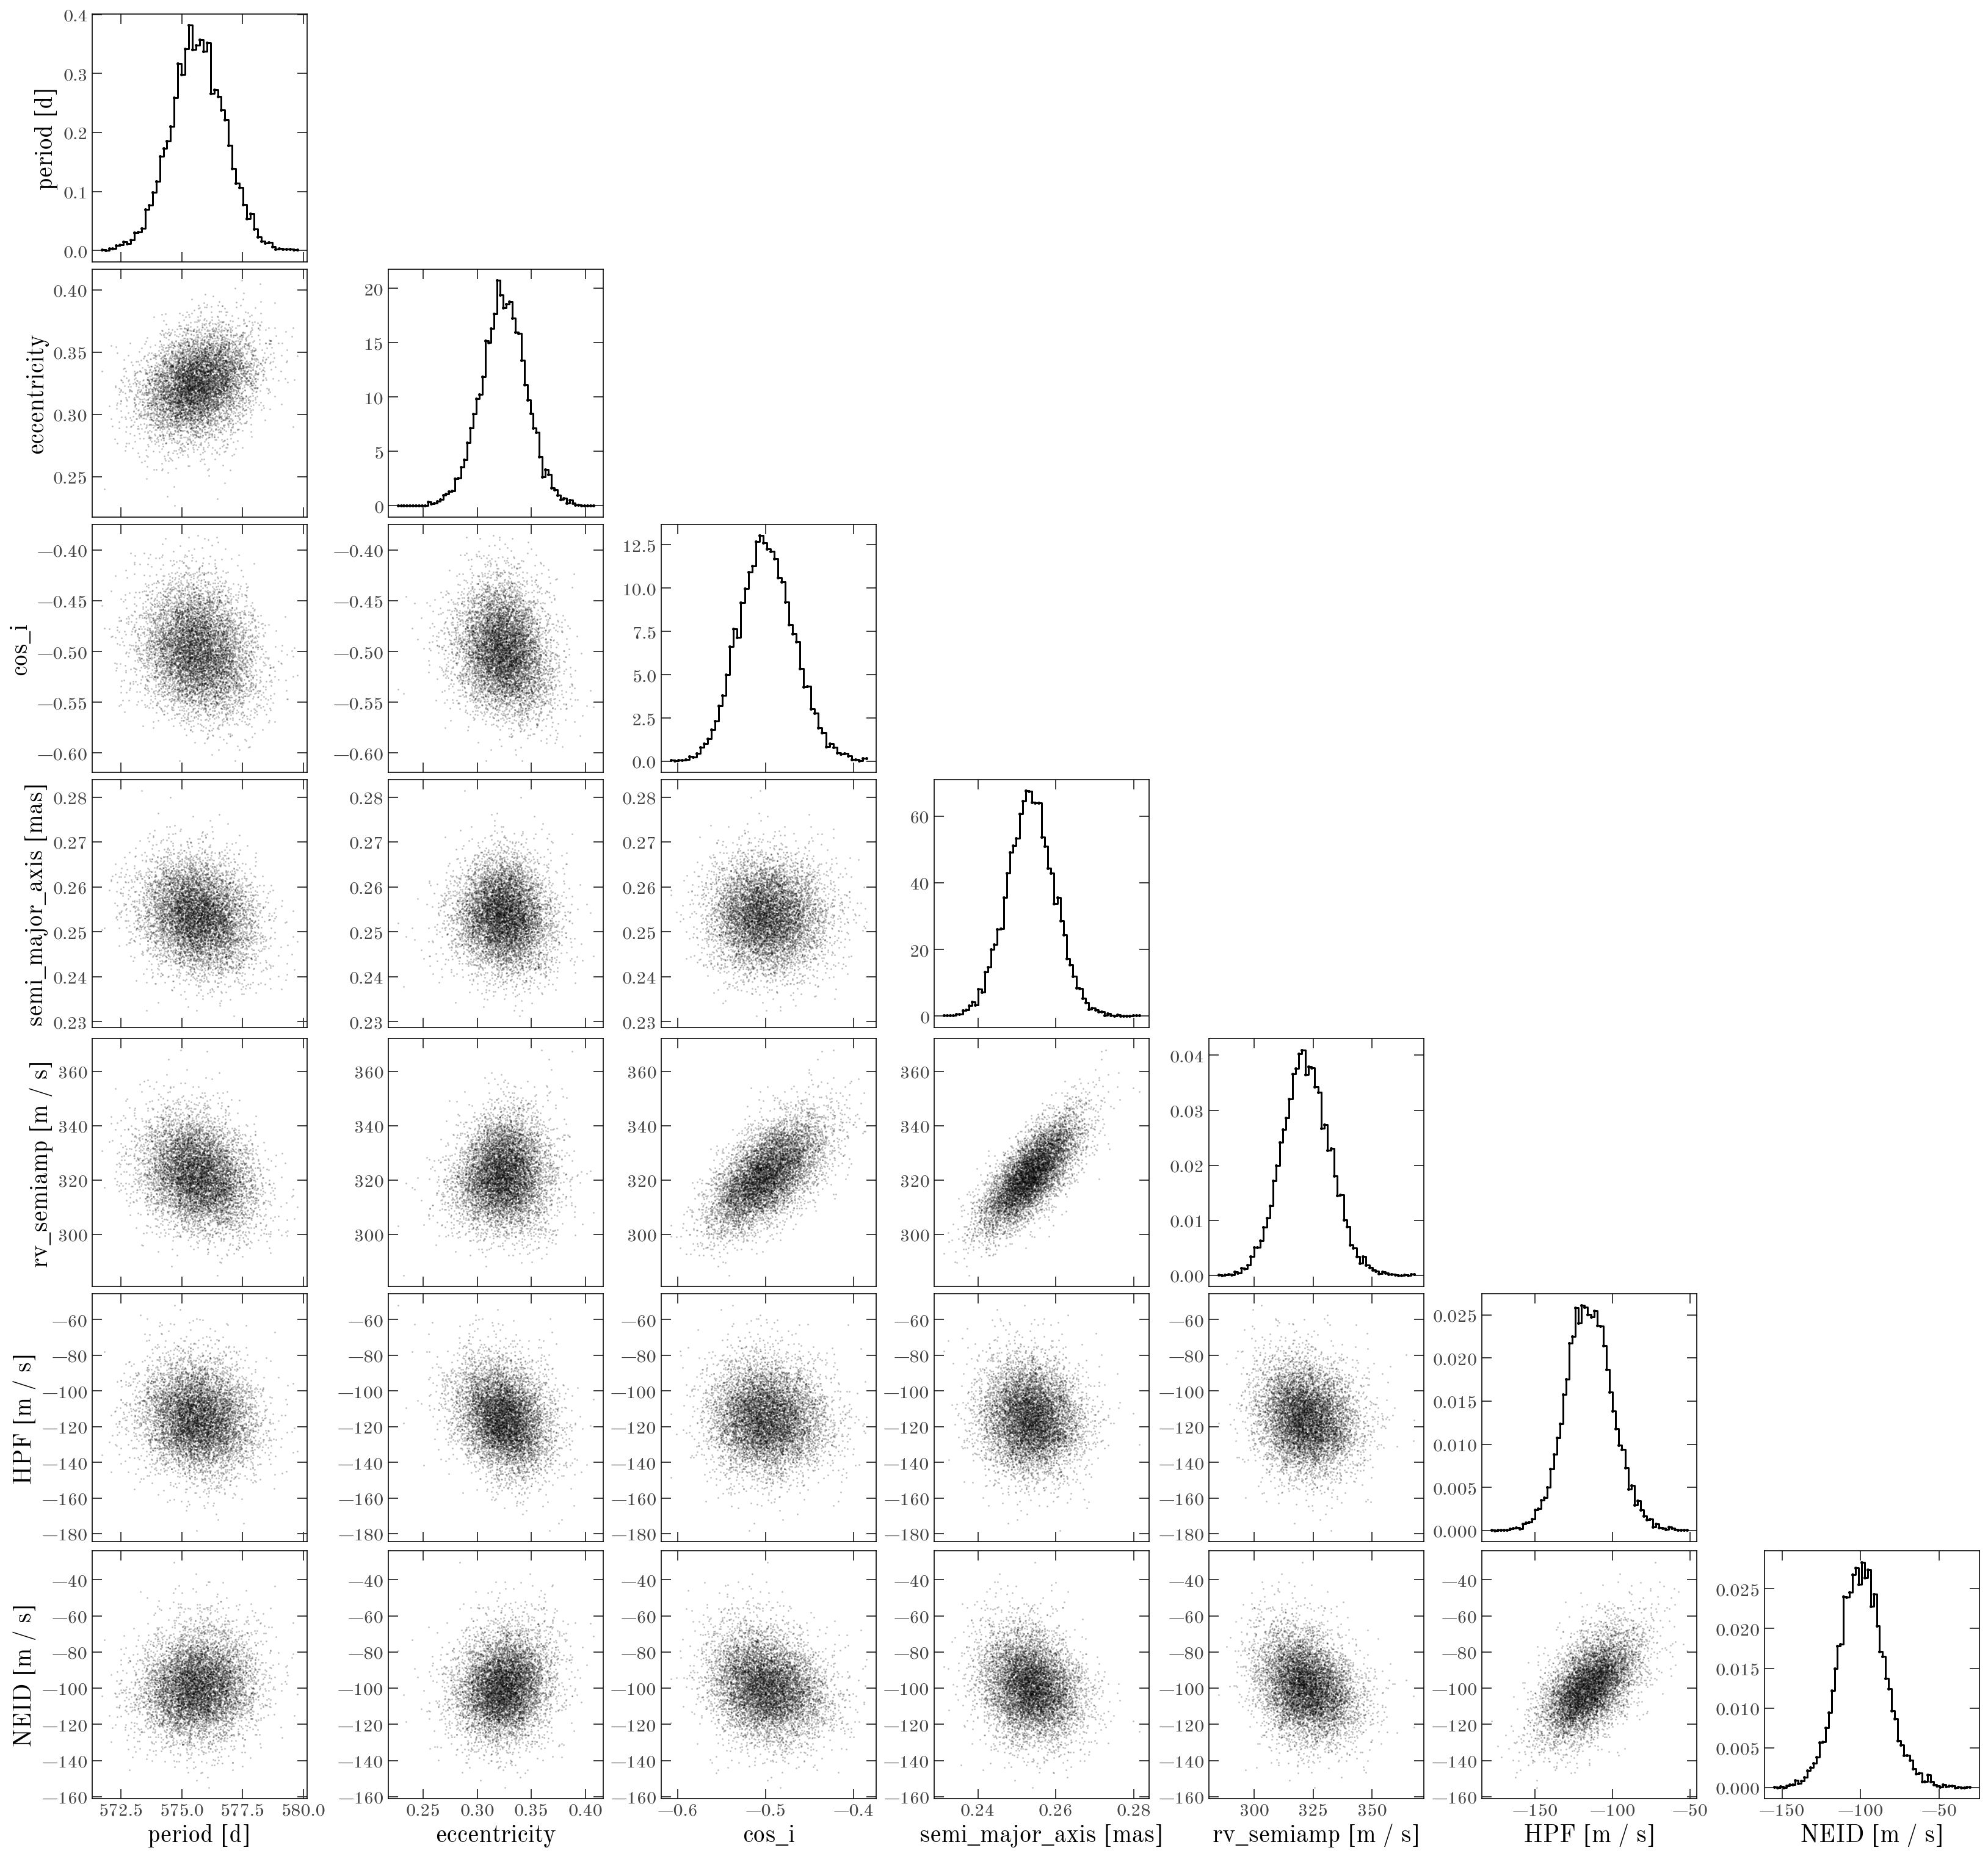

In [22]:
with rc_context({"plot.max_subplots": None}):
    _ = joint_mcmc.wrap_angles().plot_corner(
        [
            "period",
            "eccentricity",
            "cos_i",
            "semi_major_axis",
            "rv_semiamp",
            "HPF",
            "NEID",
        ],
        visuals={"scatter": {"alpha": 0.25, "s": 2}},
    )

To plot the RV orbit, we use {py:meth}`~harv.samplers.Samples.component` to get the samples for just the RV part of the joint model, and plot them against the per-instrument data with the median offsets applied:

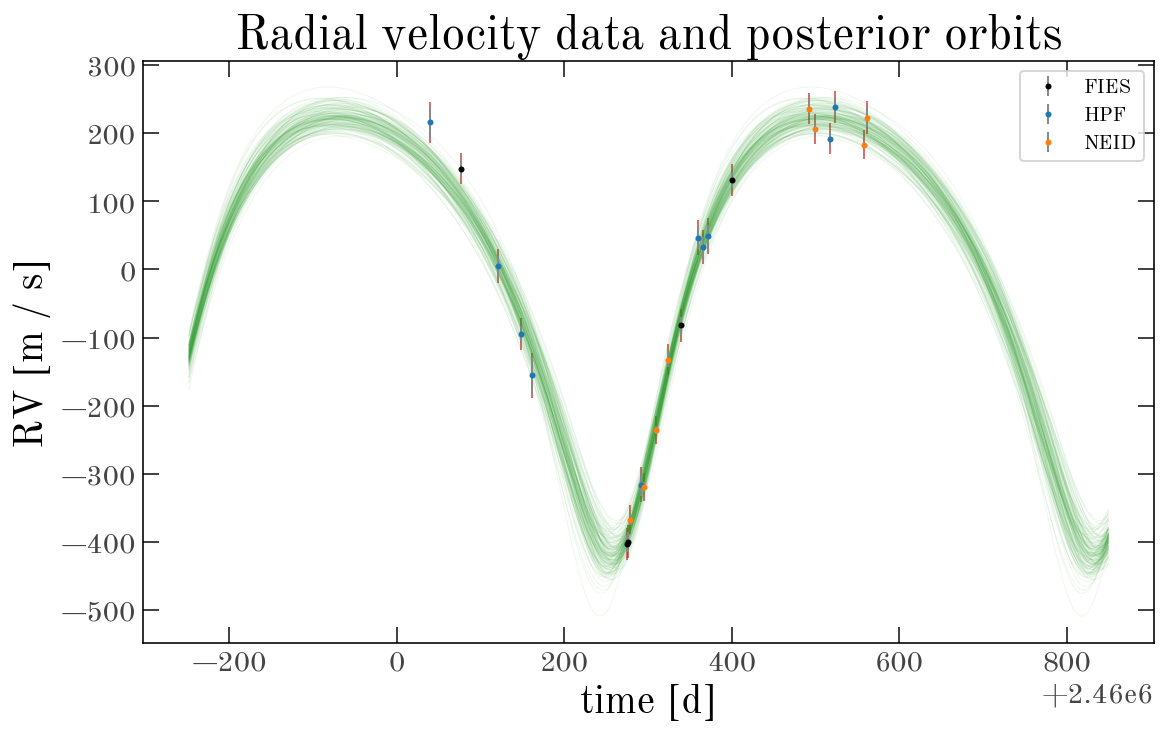

In [23]:
rv_samples = joint_mcmc.component("rv")
fig, ax = plt.subplots(figsize=(8, 5))
_ = harv.plot.plot_rv(
    rv_samples,
    data=rv_data,
    model=rv_model,
    n_samples=128,
    relative_to_median_v_sys=True,
    apply_median_offsets=True,
    ax=ax,
)

/Users/aprice-whelan/projects/harv/src/harv/plot.py:1295: UserWarning: The figure layout has changed to tight
  fig.tight_layout()


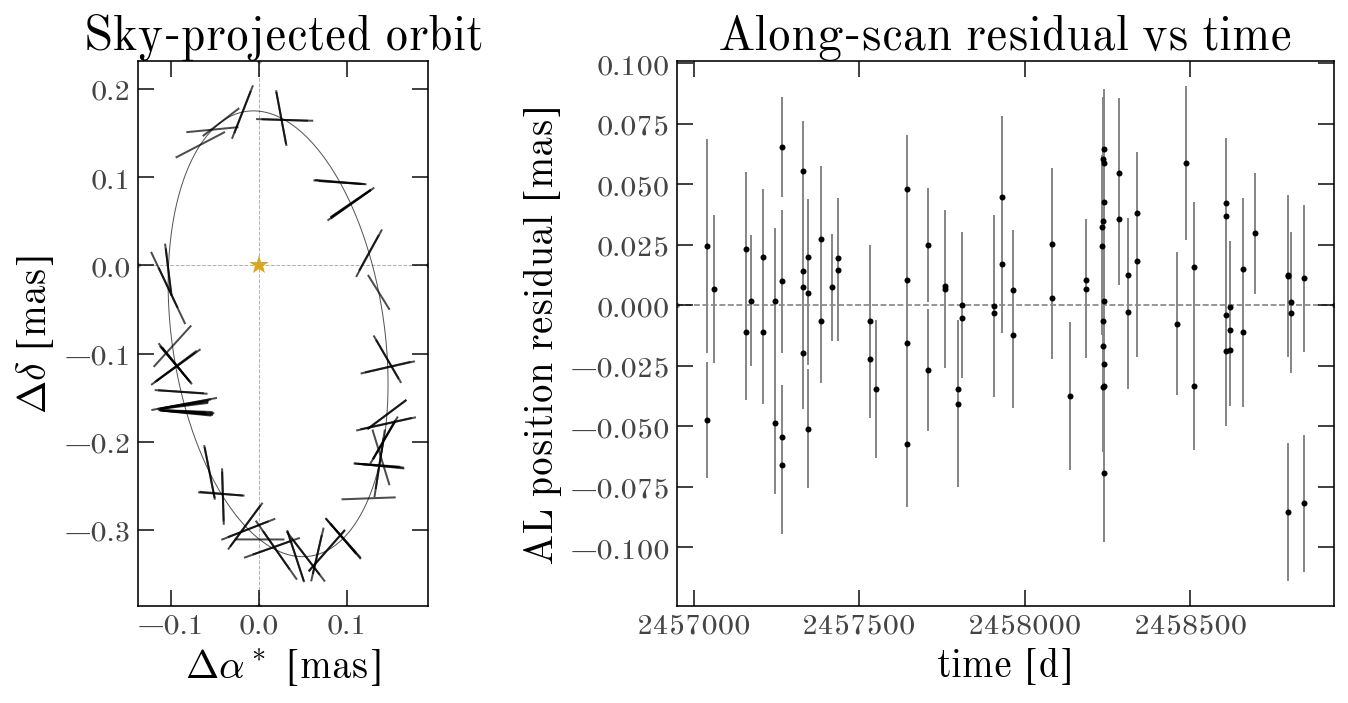

In [24]:
astrom_samples = joint_mcmc.component("astrom")
_ = harv.plot.plot_gaia_astrometry(astrom_samples.map_sample(), data=gaia_data)

### The mass of Gaia-4b

Lastly, we can estimate the mass of the companion. Because the RV semi-amplitude is tied to the astrometric orbit, the joint model has a single mass. It is mainly set by the physical size of the star's orbit. Adopting the stellar mass of $0.644~\mathrm{M}_\odot$ from Stefansson et al. (2025):

In [25]:
m_star = Q(0.644, "Msun")
m_p = joint_mcmc.component("astrom").companion_mass(m_star).to("Mjup")
lo, med, hi = np.percentile(m_p.value, [16, 50, 84])
print(f"{med:.1f} +{hi - med:.1f} -{med - lo:.1f} Mjup")

10.8 +0.3 -0.3 Mjup


This is lower than the mass of $11.8~\mathrm{M_{Jup}}$ reported by Stefansson et al. (2025), and our period ($575.4 \pm 1.2$ days) is a few days longer than their 571.3 days. Their analysis used the *Gaia* DR3 orbital solution, since the DR4 epoch astrometry were not yet available, so some difference is expected, but we have not tracked down the source of this discrepancy here.